<a href="https://colab.research.google.com/github/kunapareddysriram2007-cmyk/Deep_Learning/blob/main/Skill_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

CUDA Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [ ]:
!pip install ultralytics fastapi uvicorn python-multipart opencv-python-headless matplotlib requests -q

In [ ]:
import cv2
import torch
import time
import json
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from PIL import Image
from IPython.display import display

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

print("Selected Device:", DEVICE)

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4
Selected Device: 0


In [ ]:
model = YOLO("yolov8n.pt")

print("YOLO Model Loaded Successfully")
print("Model:", model.model.__class__.__name__)

YOLO Model Loaded Successfully
Model: DetectionModel


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

print("Received Image:", image_path)

Saving traffic_image.jpg to traffic_image.jpg
Received Image: traffic_image.jpg


Image Received Successfully
Image Shape: (533, 800, 3)
API Input Time: 28.88 ms


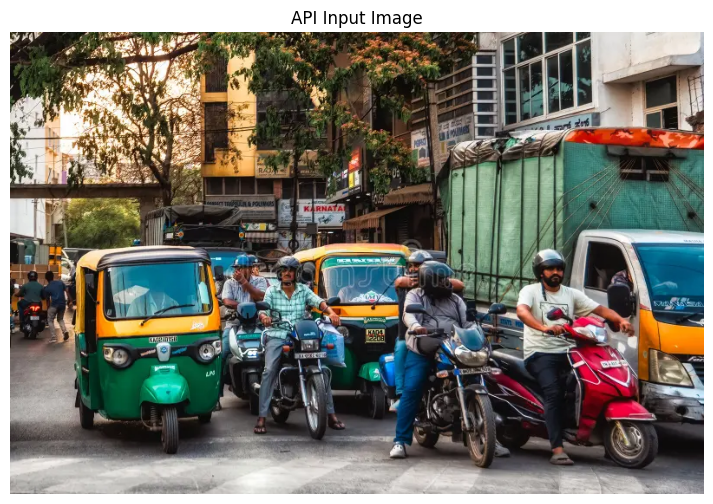

In [ ]:
start_time = time.perf_counter()

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise ValueError("Unable to read image")

api_input_time = time.perf_counter() - start_time

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Image Received Successfully")
print("Image Shape:", image_bgr.shape)
print("API Input Time:", round(api_input_time * 1000, 2), "ms")

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("API Input Image")
plt.axis("off")
plt.show()

In [ ]:
start_time = time.perf_counter()

# Resize image
processed_image = cv2.resize(
    image_bgr,
    (640, 640)
)

# Convert to RGB
processed_image = cv2.cvtColor(
    processed_image,
    cv2.COLOR_BGR2RGB
)

# Convert to tensor
input_tensor = torch.from_numpy(
    processed_image
).permute(2, 0, 1).float()

# Normalize pixel values
input_tensor = input_tensor / 255.0

# Add batch dimension
input_tensor = input_tensor.unsqueeze(0)

preprocessing_time = time.perf_counter() - start_time

print("Preprocessing Completed")
print("Tensor Shape:", input_tensor.shape)
print("Tensor Type:", input_tensor.dtype)
print("Preprocessing Time:",
      round(preprocessing_time * 1000, 2), "ms")

Preprocessing Completed
Tensor Shape: torch.Size([1, 3, 640, 640])
Tensor Type: torch.float32
Preprocessing Time: 41.26 ms


In [ ]:
# Warm-up (not included in inference timing)
_ = model.predict(
    source=image_bgr,
    imgsz=640,
    device=DEVICE,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Measure inference
start_time = time.perf_counter()

results = model.predict(
    source=image_bgr,
    imgsz=640,
    device=DEVICE,
    conf=0.25,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start_time

print("Model Execution Completed")
print("Inference Time:",
      round(inference_time * 1000, 2), "ms")

Model Execution Completed
Inference Time: 15.24 ms


In [ ]:
start_time = time.perf_counter()

detections = []

result = results[0]

for box in result.boxes:

    class_id = int(box.cls[0])

    confidence = float(box.conf[0])

    bbox = box.xyxy[0].tolist()

    class_name = model.names[class_id]

    detections.append({
        "class": class_name,
        "class_id": class_id,
        "confidence": round(confidence, 4),
        "bbox": [round(x, 2) for x in bbox]
    })

postprocessing_time = time.perf_counter() - start_time

print("Postprocessing Completed")
print("Objects Detected:", len(detections))
print("Postprocessing Time:",
      round(postprocessing_time * 1000, 2), "ms")

for detection in detections:
    print(detection)

Postprocessing Completed
Objects Detected: 15
Postprocessing Time: 31.35 ms
{'class': 'person', 'class_id': 0, 'confidence': 0.8639, 'bbox': [582.57, 250.87, 718.86, 502.45]}
{'class': 'person', 'class_id': 0, 'confidence': 0.8248, 'bbox': [437.76, 261.04, 528.87, 491.54]}
{'class': 'motorcycle', 'class_id': 3, 'confidence': 0.7196, 'bbox': [547.81, 319.66, 748.95, 504.66]}
{'class': 'person', 'class_id': 0, 'confidence': 0.7135, 'bbox': [282.28, 258.12, 383.57, 454.01]}
{'class': 'person', 'class_id': 0, 'confidence': 0.6806, 'bbox': [36.65, 274.83, 67.34, 358.53]}
{'class': 'motorcycle', 'class_id': 3, 'confidence': 0.6509, 'bbox': [281.14, 311.23, 387.2, 472.87]}
{'class': 'person', 'class_id': 0, 'confidence': 0.5975, 'bbox': [9.79, 275.39, 38.67, 347.55]}
{'class': 'car', 'class_id': 2, 'confidence': 0.5583, 'bbox': [325.95, 246.13, 460.94, 445.27]}
{'class': 'motorcycle', 'class_id': 3, 'confidence': 0.4638, 'bbox': [461.43, 317.24, 595.11, 503.61]}
{'class': 'motorcycle', 'class

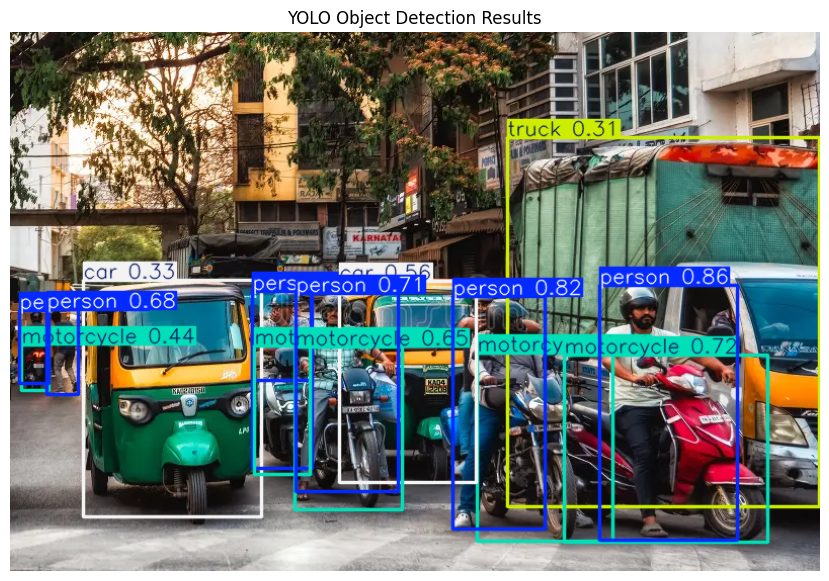

In [ ]:
annotated_image = results[0].plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_image)
plt.title("YOLO Object Detection Results")
plt.axis("off")
plt.show()

In [ ]:
total_processing_time = (
    api_input_time +
    preprocessing_time +
    inference_time +
    postprocessing_time
)

response = {
    "status": "success",

    "device": str(DEVICE),

    "image": image_path,

    "image_dimensions": {
        "height": int(image_bgr.shape[0]),
        "width": int(image_bgr.shape[1])
    },

    "total_detections": len(detections),

    "detections": detections,

    "performance": {
        "api_input_ms": round(api_input_time * 1000, 2),
        "preprocessing_ms": round(preprocessing_time * 1000, 2),
        "inference_ms": round(inference_time * 1000, 2),
        "postprocessing_ms": round(postprocessing_time * 1000, 2),
        "total_processing_ms": round(total_processing_time * 1000, 2)
    }
}

print(json.dumps(response, indent=4))

{
    "status": "success",
    "device": "0",
    "image": "traffic_image.jpg",
    "image_dimensions": {
        "height": 533,
        "width": 800
    },
    "total_detections": 15,
    "detections": [
        {
            "class": "person",
            "class_id": 0,
            "confidence": 0.8639,
            "bbox": [
                582.57,
                250.87,
                718.86,
                502.45
            ]
        },
        {
            "class": "person",
            "class_id": 0,
            "confidence": 0.8248,
            "bbox": [
                437.76,
                261.04,
                528.87,
                491.54
            ]
        },
        {
            "class": "motorcycle",
            "class_id": 3,
            "confidence": 0.7196,
            "bbox": [
                547.81,
                319.66,
                748.95,
                504.66
            ]
        },
        {
            "class": "person",
            "class

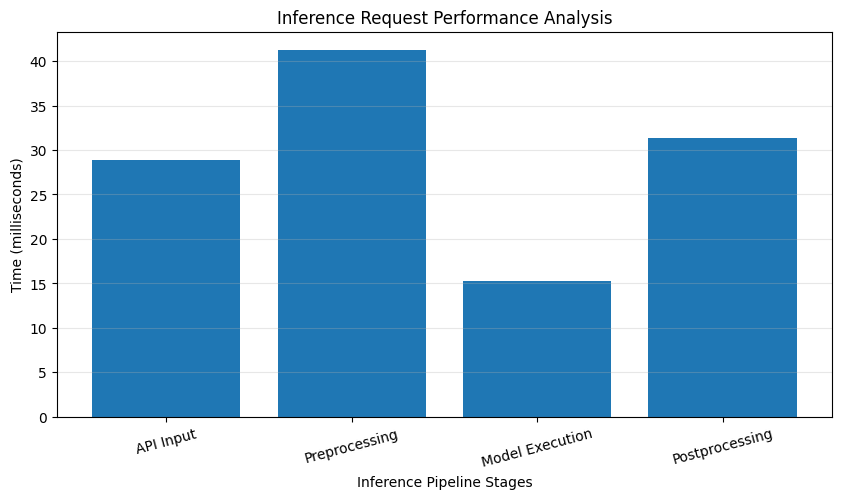

Total Pipeline Time: 116.73 ms
Model Inference Time: 15.24 ms


In [ ]:
stages = [
    "API Input",
    "Preprocessing",
    "Model Execution",
    "Postprocessing"
]

times = [
    api_input_time * 1000,
    preprocessing_time * 1000,
    inference_time * 1000,
    postprocessing_time * 1000
]

plt.figure(figsize=(10, 5))

plt.bar(stages, times)

plt.ylabel("Time (milliseconds)")
plt.xlabel("Inference Pipeline Stages")
plt.title("Inference Request Performance Analysis")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Total Pipeline Time:",
      round(sum(times), 2), "ms")

print("Model Inference Time:",
      round(inference_time * 1000, 2), "ms")

In [ ]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import JSONResponse
from io import BytesIO

app = FastAPI(title="VisionPort Inference API")

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image"
        )

    request_start = time.perf_counter()

    image_bytes = await file.read()

    image_array = np.frombuffer(
        image_bytes,
        dtype=np.uint8
    )

    image = cv2.imdecode(
        image_array,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise HTTPException(
            status_code=400,
            detail="Invalid image file"
        )

    api_input_ms = (
        time.perf_counter() - request_start
    ) * 1000

    start = time.perf_counter()

    results = model.predict(
        source=image,
        imgsz=640,
        device=DEVICE,
        conf=0.25,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inference_ms = (
        time.perf_counter() - start
    ) * 1000

    start = time.perf_counter()

    detections = []

    for box in results[0].boxes:

        class_id = int(box.cls[0])

        detections.append({
            "class": model.names[class_id],
            "confidence": round(float(box.conf[0]), 4),
            "bbox": [
                round(x, 2)
                for x in box.xyxy[0].tolist()
            ]
        })

    postprocessing_ms = (
        time.perf_counter() - start
    ) * 1000

    total_ms = (
        time.perf_counter() - request_start
    ) * 1000

    return {
        "status": "success",
        "total_detections": len(detections),
        "detections": detections,
        "performance": {
            "api_input_ms": round(api_input_ms, 2),
            "inference_ms": round(inference_ms, 2),
            "postprocessing_ms": round(postprocessing_ms, 2),
            "total_request_ms": round(total_ms, 2)
        }
    }

In [ ]:
import threading
import uvicorn
import time

config = uvicorn.Config(
    app,
    host="0.0.0.0",
    port=8000,
    log_level="warning"
)

server = uvicorn.Server(config)

thread = threading.Thread(
    target=server.run,
    daemon=True
)

thread.start()

time.sleep(2)

print("FastAPI server started!")

FastAPI server started!


In [ ]:
import requests

with open(image_path, "rb") as f:

    response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={
            "file": (
                image_path,
                f,
                "image/jpeg"
            )
        }
    )

print("Status Code:", response.status_code)

print(json.dumps(response.json(), indent=4))


Status Code: 200
{
    "status": "success",
    "total_detections": 15,
    "detections": [
        {
            "class": "person",
            "confidence": 0.8639,
            "bbox": [
                582.57,
                250.87,
                718.86,
                502.45
            ]
        },
        {
            "class": "person",
            "confidence": 0.8248,
            "bbox": [
                437.76,
                261.04,
                528.87,
                491.54
            ]
        },
        {
            "class": "motorcycle",
            "confidence": 0.7196,
            "bbox": [
                547.81,
                319.66,
                748.95,
                504.66
            ]
        },
        {
            "class": "person",
            "confidence": 0.7135,
            "bbox": [
                282.28,
                258.12,
                383.57,
                454.01
            ]
        },
        {
            "class": "pers